# MLH1 Story

In [1]:
import polars as pl
import seaborn as sns

In [3]:
integrative_scores = pl.read_csv(
    "../../3_integrated_assay_results/3_outputs/0_all_gene_variants_assayed_summary.tsv",
    separator="\t",
    infer_schema_length=100000)
integrative_scores

imaging_detailed_analyses = pl.read_csv("../../2_individual_assay_results/imaging/3_outputs/3_img_pheno_var_clustering_results.csv")
imaging_detailed_analyses_mlh1 = imaging_detailed_analyses.filter(
    pl.col("Metadata_gene_allele").str.contains("MLH1")
)
ppi_detailed_analyses = pl.read_csv("../../2_individual_assay_results/ppi/3_outputs/sqY2H/7_edge_perturbation_categorical.csv", infer_schema_length=100000)

ppi_detailed_analyses_mlh1 = ppi_detailed_analyses.join(
    integrative_scores.filter(
        pl.col("symbol")=="MLH1",
    ),
    left_on=["db_orf_id","db_mut_id"],
    right_on=["orf_id", "mut_id"],
    how="inner"
)

In [4]:
integrative_scores.filter(
    pl.col("symbol").str.contains("MLH1")
).select('gene_variant','clinvar_clnsig_clean')

gene_variant,clinvar_clnsig_clean
str,str
"""MLH1_Ala586Asp""","""Pathogenic"""
"""MLH1_Ala681Thr""","""Pathogenic"""
"""MLH1_Asp304Gly""","""Conflicting"""
"""MLH1_Asp485Glu""","""Others"""
"""MLH1_Cys39Tyr""","""VUS"""
…,…
"""MLH1_Ser106Arg""","""VUS"""
"""MLH1_Ser295Thr""","""VUS"""
"""MLH1_Ser44Phe""","""Pathogenic"""


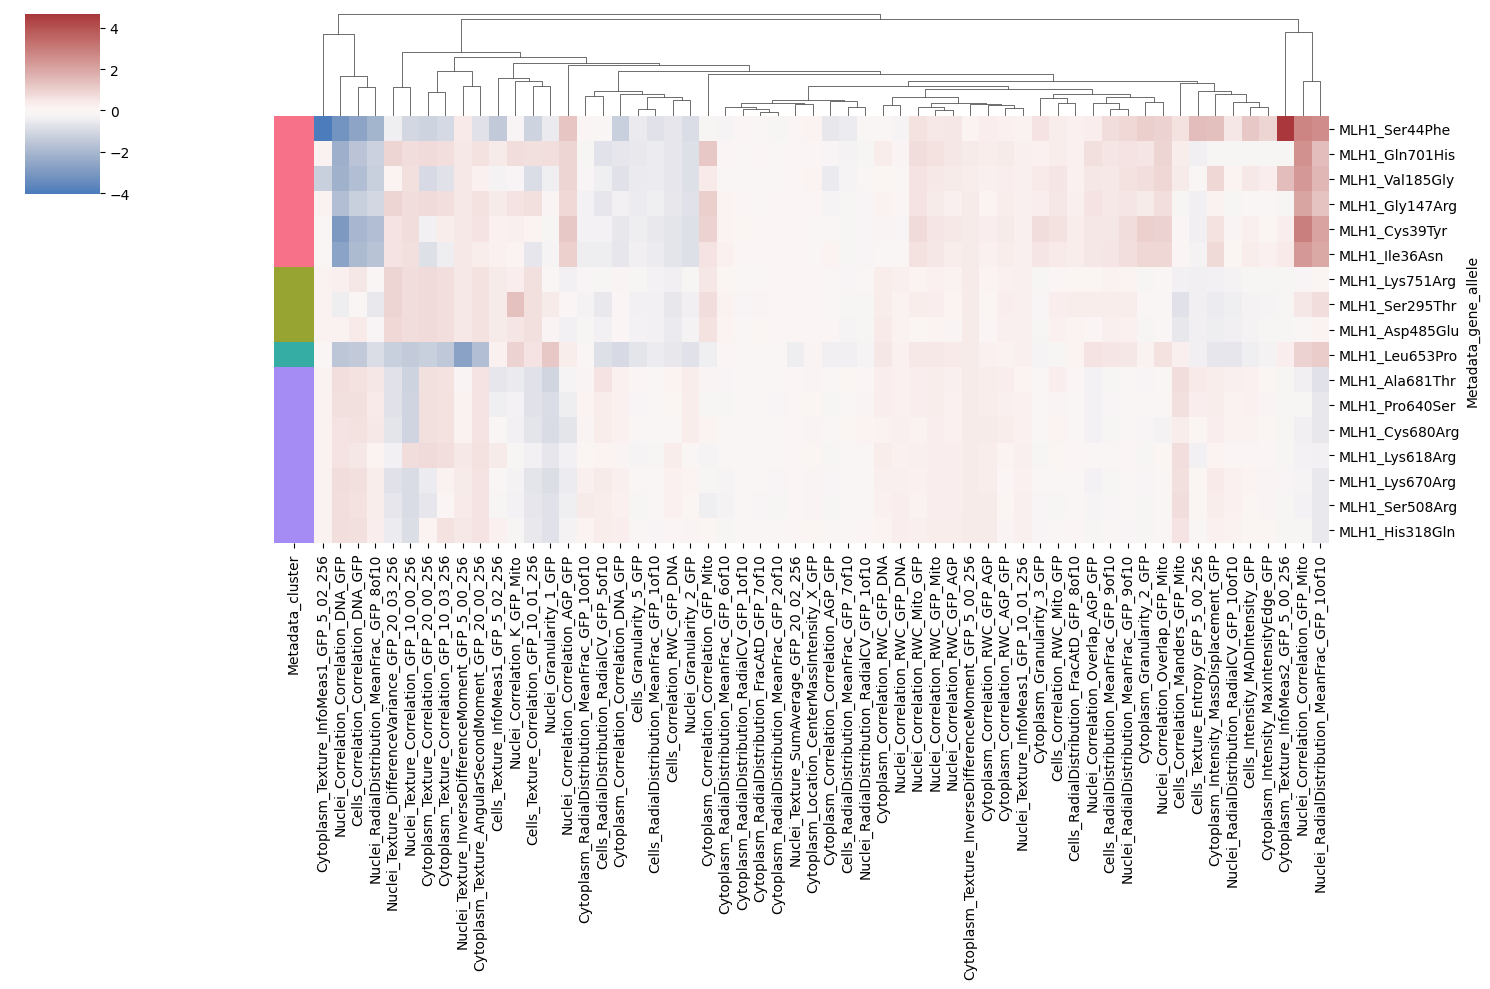

In [5]:
import matplotlib.pyplot as plt

imaging_detailed_analyses_mlh1 = imaging_detailed_analyses_mlh1.sort("Metadata_cluster")

# Convert to pandas and create color mapping
data_pd = imaging_detailed_analyses_mlh1.select(
    [c for c in imaging_detailed_analyses_mlh1.columns if "Metadata" not in c] + ["Metadata_gene_allele"]
).to_pandas().set_index("Metadata_gene_allele")

clusters_pd = imaging_detailed_analyses_mlh1.select(["Metadata_cluster"]).to_pandas()
unique_clusters = clusters_pd["Metadata_cluster"].unique()
palette = sns.color_palette("husl", len(unique_clusters))
cluster_colors = {cluster: palette[i] for i, cluster in enumerate(sorted(unique_clusters))}

# Map clusters to colors - reset index to match data_pd index
row_colors_mapped = clusters_pd["Metadata_cluster"].map(cluster_colors)
row_colors_mapped.index = data_pd.index

sns.clustermap(
    data=data_pd,
    row_cluster=False,
    row_colors=row_colors_mapped,
    cmap="vlag",
    center=0,
    xticklabels=1,
    figsize=(15, 10)
)

plt.show()